# Evaluasi Offline Sistem Rekomendasi Kuliner KNN

Tugas Kelompok 2 (TK2) — Sains Data, Informatika, Universitas Udayana.

Notebook ini adalah **bagian 4 dari 7**. Metrik dihitung dari 40 skenario kueri pada katalog GoFood Jabodetabek & Bandung (10.261 merchant) dan membandingkan S1–S4 (Tabel 3.18 laporan TK1) plus baseline rating.

Anggota: Ketut Indhira Ayu Maheswari (2408561010), Ida Ayu Prami Suari (2408561040), Kadek Ezra Mahanaim (2408561052), I Kadek Dillon Satria Prabawa (2408561141). Dosen: I Made Satria Bimantara, S.Kom., M.Kom.

> **Peringatan penting.** Precision@K dan NDCG@K pada notebook ini memakai **relevansi proksi** aturan Subbab 3.8.1, *bukan* penilaian pengguna. Aturan itu memakai irisan kategori, rating ≥ 4,7, dan jarak ≤ R/2 — atribut yang tumpang tindih dengan skor. Hasilnya condong menguntungkan model yang menekan kategori (dan rating untuk nilai 2), **tidak** boleh diklaim sebagai kualitas akhir sistem. Penilaian responden (0/1/2) menyusul di bagian 5.


## 1. Tujuan dan ruang lingkup

Bagian ini mengisi evaluasi *offline* yang dapat dijalankan tanpa responden:

1. menghitung Precision@K dan NDCG@K dengan relevansi proksi pada 40 kueri;
2. membandingkan S1 (jarak), S2 (jarak + kategori), S3 (jarak + kategori + rating), S4 (skor penuh), dan baseline rating;
3. mengukur metrik pendukung tanpa label: cakupan katalog, diversitas intra-daftar, jarak/rating rata-rata, ketepatan anggaran, dan keunikan merek;
4. menguji beda berpasangan S4 lawan baseline dengan Wilcoxon bertanda (α = 0,05);
5. melihat sensitivitas radius (S6) dan grid bobot (S5, langkah 0,05).

Luaran skrip `scripts/evaluasi_offline.py` sudah disimpan di `reports/evaluasi_offline/`. Sel berikut **memuat hasil itu**, bukan menghitung ulang grid (perhitungan penuh sekitar 1–2 menit).


In [1]:
from pathlib import Path
import json
import sys

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path("..").resolve()
if not (ROOT / "src" / "kuliner").exists():
    ROOT = Path(".").resolve()
SRC = ROOT / "src"
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

LAPORAN = ROOT / "reports" / "evaluasi_offline"
pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

skenario = pd.read_csv(ROOT / "data" / "evaluasi" / "skenario.csv")
ringkasan = pd.read_csv(LAPORAN / "ringkasan.csv")
hasil = pd.read_csv(LAPORAN / "hasil_per_skenario.csv")
s6 = pd.read_csv(LAPORAN / "sensitivitas_radius.csv")
s5 = pd.read_csv(LAPORAN / "grid_bobot.csv")
wilcox = json.loads((LAPORAN / "wilcoxon.json").read_text(encoding="utf-8"))
meta = json.loads((LAPORAN / "meta.json").read_text(encoding="utf-8"))

print(f"Katalog: {meta['n_katalog']} merchant.")
print(f"Skenario: {meta['n_skenario']} kueri, {meta['n_kota']} kota.")
print("Berkas laporan:", ", ".join(sorted(p.name for p in LAPORAN.iterdir())))


Katalog: 10261 merchant.
Skenario: 40 kueri, 18 kota.
Berkas laporan: cakupan_katalog.png, grid_bobot.csv, hasil_per_skenario.csv, jarak_diversitas_boxplot.png, meta.json, p10_ndcg_boxplot.png, ringkasan.csv, sensitivitas_radius.csv, sensitivitas_radius.png, wilcoxon.json


## 2. Metrik

Rumus mengikuti Bab 2 dan Subbab 3.8.1 laporan TK1. Implementasinya ada di `src/kuliner/evaluasi.py` dan **siap menerima penilaian responden** pada bagian 5 (cukup mengganti daftar nilai relevansi).

**Precision@K** (Persamaan 2.4). Nilai graded diubah ke biner: 1 jika \(\mathrm{rel}_i \ge 1\), selain itu 0. Pembagi selalu \(K\), item yang kurang dari \(K\) dianggap tidak relevan.

\[
\mathrm{Precision@}K = \frac{1}{K}\sum_{i=1}^{K} \mathrm{rel}_i,\qquad \mathrm{rel}_i \in \{0,1\}
\]

**DCG@K** dan **NDCG@K** (Persamaan 2.5–2.6) memakai nilai graded 0/1/2. IDCG dihitung dari nilai yang sama, diurutkan menurun. Jika semua nilai 0, NDCG = 0.

\[
\mathrm{DCG@}K = \sum_{i=1}^{K} \frac{2^{\mathrm{rel}_i}-1}{\log_2(i+1)},\qquad
\mathrm{NDCG@}K = \frac{\mathrm{DCG@}K}{\mathrm{IDCG@}K}
\]

**Relevansi proksi** (bukan penilaian manusia):

- 2 jika kategori beririsan **dan** rating ≥ 4,7 **dan** jarak ≤ \(R/2\);
- 1 jika hanya kategori yang beririsan;
- 0 untuk lainnya.

Jika pengguna tidak memilih kategori, irisan tidak dapat dihitung. Perluasan yang dicatat: 2 jika syarat rating dan jarak terpenuhi, 1 jika salah satu, 0 jika tidak.

Metrik pendukung: **cakupan katalog** (Persamaan 3.7) \(|\bigcup \mathrm{TopN}(q)|\,/\,|I|\times 100\%\); **diversitas intra-daftar** = rata-rata \(1-\mathrm{Jaccard}\) antarhim punan kategori; jarak dan rating rata-rata; **price-fit** = proporsi item dengan `price_level` ≤ anggaran; **keunikan merek** \(=-\log_2(\mathrm{frekuensi\ merek}/|I|)\) karena dataset tidak punya jumlah ulasan.


## 3. Skenario kueri

Empat puluh kueri dibangkitkan dengan biji acak 42. Setiap kueri memakai centroid merchant di suatu kota–kecamatan (syarat yang sama dengan antarmuka: ≥ 5 merchant). Ke-18 kota terwakili. Variasi mencakup radius 1/3/5/10 km, anggaran 1–4, ambang rating 0 / 4,0 / 4,5 / 4,7, satu atau dua kategori, dua kueri tanpa kategori, dan dua kueri dengan \(k=5\) (metrik @5 dan @10 tetap dihitung untuk semua kueri dari daftar Top-10). `Q01` adalah kasus demonstrasi TK1 (Kota Depok – Beji, Bakmie).


In [2]:
print("Sebaran kueri per kota:")
display(skenario.groupby("kota").size().rename("n_kueri").to_frame().T)

print("Q01 (kasus TK1) dan beberapa variasi:")
tampil = skenario.loc[skenario["id"].isin(["Q01", "Q19", "Q23", "Q27", "Q30", "Q34", "Q40"]),
                      ["id", "kota", "kecamatan", "radius_km", "budget_maks", "rating_min", "kategori", "k", "catatan"]]
display(tampil.reset_index(drop=True))
print("Radius unik:", sorted(skenario.radius_km.unique().tolist()),
      "| anggaran:", sorted(skenario.budget_maks.unique().tolist()),
      "| rating_min:", sorted(skenario.rating_min.unique().tolist()))


Sebaran kueri per kota:


kota,Jakarta Barat,Jakarta Pusat,Jakarta Selatan,Jakarta Timur,Jakarta Utara,Kabupaten Bandung,Kabupaten Bandung Barat,Kabupaten Bekasi,Kabupaten Bogor,Kabupaten Sumedang,Kabupaten Tangerang,Kota Bandung,Kota Bekasi,Kota Bogor,Kota Cimahi,Kota Depok,Kota Tangerang,Kota Tangerang Selatan
n_kueri,3,3,4,2,2,1,2,1,2,2,2,4,2,2,2,2,2,2


Q01 (kasus TK1) dan beberapa variasi:


,id,kota,kecamatan,radius_km,budget_maks,rating_min,kategori,k,catatan
0,Q01,Kota Depok,Beji,5,2,4.5000,Bakmie,10,"Kasus demonstrasi TK1 (Beji, Bakmie)"
1,Q19,Jakarta Selatan,Kebayoran Baru,1,3,4.0000,Kopi,10,"Radius ketat 1 km, Kopi"
2,Q23,Jakarta Timur,Cakung,5,1,4.0000,Aneka nasi,10,Anggaran hemat (level 1)
3,Q27,Kota Bandung,Cicendo,5,3,4.5000,Kopi|Sweets,10,Dua kategori: Kopi dan Sweets
4,Q30,Kota Cimahi,Cibeber,5,2,4.5000,NaN,10,Tanpa pilihan kategori (bobot kategori dinolkan)
5,Q34,Jakarta Selatan,Tebet,5,3,4.0000,India,10,Kategori jarang: India
6,Q40,Kota Depok,Cinere,5,2,4.5000,Cepat saji,5,"Variasi Depok (Cinere), Top-5"


Radius unik: [1, 3, 5, 10] | anggaran: [1, 2, 3, 4] | rating_min: [0.0, 4.0, 4.5, 4.7]


## 4. Hasil utama: Precision@K dan NDCG@K (proksi)

Kelima metode memakai filter keras yang sama (radius, anggaran, rating minimum, dan kategori jika dipilih). Yang berbeda hanya cara mengurutkan kandidat.


,P@5,P@10,NDCG@5,NDCG@10,Cakupan (%),Diversitas,Jarak rata (km),Rating rata,Price-fit,Keunikan merek
Metode,,,,,,,,,,
S1 jarak saja,0.1750,0.1950,0.2676,0.3458,3.5279,0.8478,0.7148,4.6648,1.0000,11.4287
S2 jarak + kategori,0.8800,0.8075,0.9167,0.9037,3.7033,0.5152,1.8009,4.6561,1.0000,11.3613
S3 jarak + kategori + rating,0.8800,0.7975,0.9231,0.9167,3.7033,0.5234,1.7937,4.6787,1.0000,11.2353
S4 skor penuh (usulan),0.8600,0.7850,0.9175,0.9106,3.6839,0.5304,1.8039,4.6677,1.0000,11.4143
Baseline rating saja,0.2250,0.2175,0.3801,0.4233,2.9432,0.8095,2.2349,4.8325,1.0000,11.3401


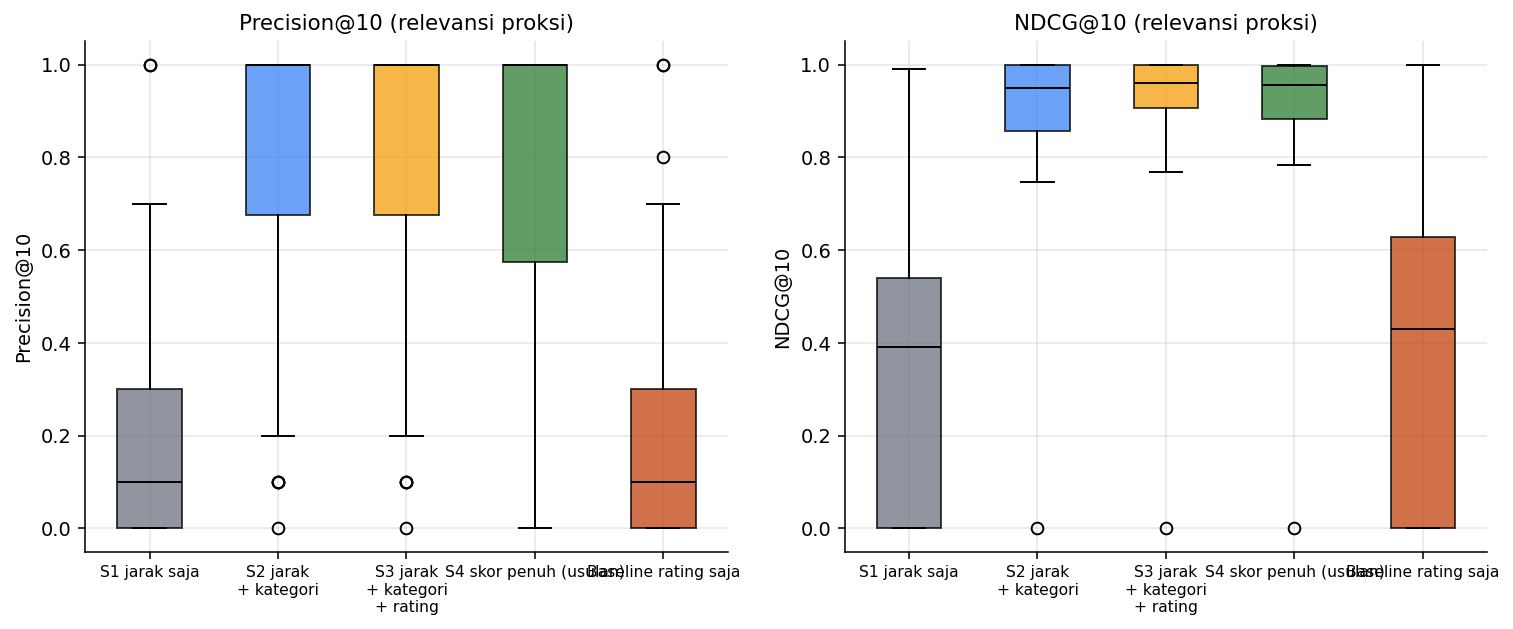

In [3]:
kolom = [
    "label_metode", "precision_at_5_rata", "precision_at_10_rata",
    "ndcg_at_5_rata", "ndcg_at_10_rata", "cakupan_pct",
    "diversitas_rata", "jarak_rata", "rating_rata", "price_fit_rata", "keunikan_rata",
]
display(ringkasan[kolom].rename(columns={
    "label_metode": "Metode",
    "precision_at_5_rata": "P@5",
    "precision_at_10_rata": "P@10",
    "ndcg_at_5_rata": "NDCG@5",
    "ndcg_at_10_rata": "NDCG@10",
    "cakupan_pct": "Cakupan (%)",
    "diversitas_rata": "Diversitas",
    "jarak_rata": "Jarak rata (km)",
    "rating_rata": "Rating rata",
    "price_fit_rata": "Price-fit",
    "keunikan_rata": "Keunikan merek",
}).set_index("Metode"))

display(Image(filename=str(LAPORAN / "p10_ndcg_boxplot.png")))


**Bacaan singkat (ingat: ini proksi, bukan responden).**

- Baseline jarak (S1) dan baseline rating kalah jauh pada P@10 dan NDCG@10. Wajar: proksi memberi nilai 1 segera setelah kategori beririsan, sementara S1 tidak menekan kategori sama sekali.
- S2 (jarak + kategori) mencatat P@10 rata-rata tertinggi (0,8075). S3 (ditambah rating) mencatat NDCG@10 tertinggi (0,9167). S4 (skor penuh, termasuk harga) sedikit di bawah keduanya (P@10 0,7850; NDCG@10 0,9106).
- Itu tidak aneh. Filter keras sudah memotong item di atas anggaran, dan **aturan proksi tidak memakai harga**. Bobot harga pada S4 hanya menggeser urutan, kadang menurunkan item yang proksinya tinggi.
- Median P@10 S2/S3/S4 = 1,0: pada banyak kueri, sepuluh item teratas semuanya beririsan kategori. Perbedaan antarmodel gabungan terkonsentrasi di sedikit kueri.


## 5. Metrik pendukung tanpa label


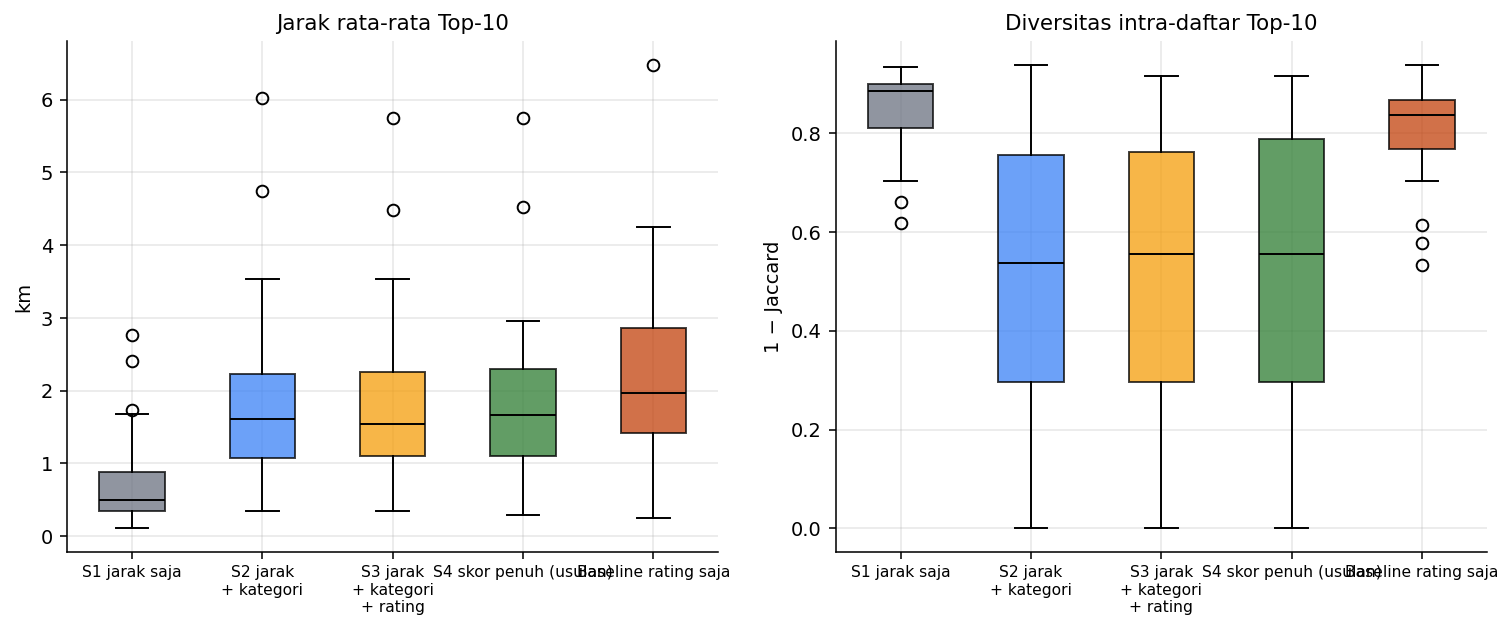

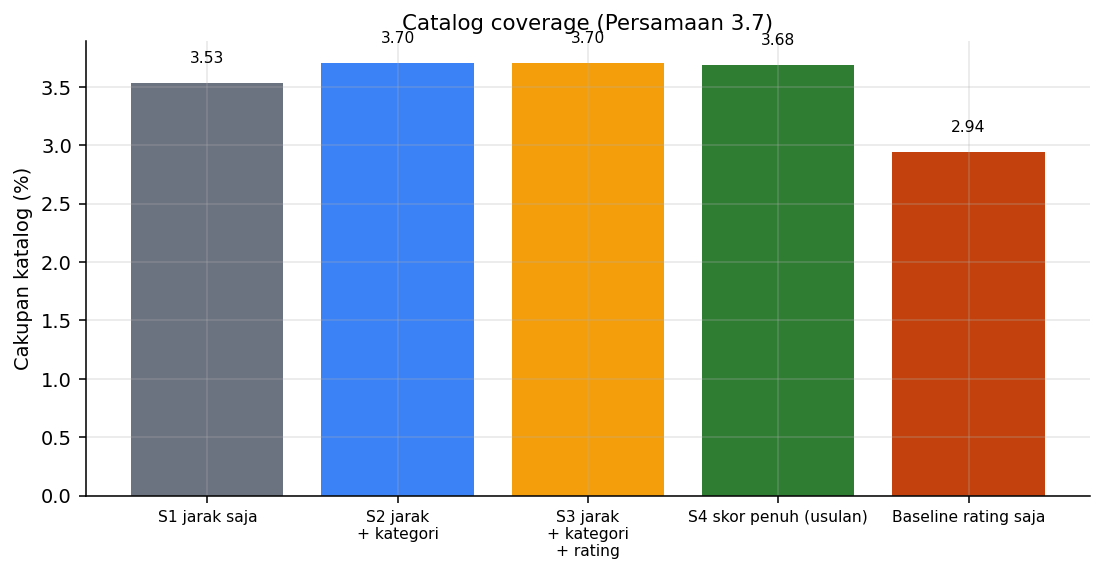

Price-fit rata-rata semua metode = 1,0: filter keras anggaran tidak dilanggar.
Cakupan katalog kecil (~3–3,7%) memang diharapkan:
40 kueri × 10 item = paling banyak 400 identitas unik / 10.261 ≈ 3,9%.


In [4]:
display(Image(filename=str(LAPORAN / "jarak_diversitas_boxplot.png")))
display(Image(filename=str(LAPORAN / "cakupan_katalog.png")))

print("Price-fit rata-rata semua metode = 1,0: filter keras anggaran tidak dilanggar.")
print("Cakupan katalog kecil (~3–3,7%) memang diharapkan:")
print("40 kueri × 10 item = paling banyak 400 identitas unik / 10.261 ≈ 3,9%.")


- **Jarak rata-rata** paling rendah pada S1 (0,71 km) karena acuan pengurutan adalah jarak. S2–S4 sekitar 1,80 km; baseline rating 2,23 km (merchant berating tinggi bisa jauh di dalam radius).
- **Diversitas** justru paling tinggi pada S1 dan baseline rating (~0,81–0,85): daftar tercampur kategori. S2–S4 lebih homogen (~0,52) karena kategori ditekan — konsekuensi yang perlu diingat jika keberagaman daftar dianggap penting.
- **Keunikan merek** hampir seragam antar metode; popularitas merek bukan sinyal yang dipakai skor.
- **Cakupan** S1–S4 berdekatan; baseline rating sedikit lebih rendah (merchant populer/berating tinggi cenderung berulang antarkueri).


## 6. Uji Wilcoxon bertanda (berpasangan, α = 0,05)

Setiap kueri menghasilkan satu angka metrik per metode. Selisih (S4 − lawan) diuji dengan Wilcoxon; selisih nol dibuang (`zero_method='wilcox'`). Hipotesis nol: median selisih = 0.


In [5]:
baris = []
for kunci, uji in wilcox.items():
    baris.append({
        "Perbandingan": f"{uji['metode_a']} vs {uji['metode_b']}",
        "Metrik": uji["metrik"],
        "n dipakai": uji["n_dipakai"],
        "n selisih 0": uji["n_selisih_nol"],
        "Median selisih (S4 − lawan)": uji["median_selisih"],
        "Rata-rata selisih": uji["rata_selisih"],
        "Statistik W": uji["statistik"],
        "p-value": uji["p_value"],
        "Signifikan (α=0,05)": "Ya" if uji["signifikan"] else "Tidak",
    })
tabel_w = pd.DataFrame(baris)
display(tabel_w)
display(Markdown(
    "Selisih positif berarti S4 lebih tinggi. "
    "S4 unggul sangat jelas terhadap S1 dan baseline rating "
    f"(p ≈ {wilcox['S4_penuh_vs_S1_jarak__precision_at_10']['p_value']:.2e} untuk P@10 vs S1). "
    "Terhadap S2, rata-rata selisih P@10 = "
    f"{wilcox['S4_penuh_vs_S2_jarak_kategori__precision_at_10']['rata_selisih']:.4f} "
    "(S2 sedikit lebih tinggi; p = "
    f"{wilcox['S4_penuh_vs_S2_jarak_kategori__precision_at_10']['p_value']:.3f}, "
    "hanya 6 kueri tanpa ikatan). Terhadap S3, beda P@10 tidak signifikan "
    f"(p = {wilcox['S4_penuh_vs_S3_tanpa_harga__precision_at_10']['p_value']:.3f})."
))


,Perbandingan,Metrik,n dipakai,n selisih 0,Median selisih (S4 − lawan),Rata-rata selisih,Statistik W,p-value,"Signifikan (α=0,05)"
0,S4_penuh vs S1_jarak,precision_at_10,35,5,0.7000,0.5900,0.0000,0.0000,Ya
1,S4_penuh vs S1_jarak,ndcg_at_10,39,1,0.5523,0.5648,3.0000,0.0000,Ya
2,S4_penuh vs S_rating,precision_at_10,35,5,0.6000,0.5675,0.0000,0.0000,Ya
3,S4_penuh vs S_rating,ndcg_at_10,39,1,0.4496,0.4874,8.0000,0.0000,Ya
4,S4_penuh vs S2_jarak_kategori,precision_at_10,6,34,0.0000,-0.0225,0.0000,0.0235,Ya
5,S4_penuh vs S3_tanpa_harga,precision_at_10,4,36,0.0000,-0.0125,0.0000,0.0588,Tidak


Selisih positif berarti S4 lebih tinggi. S4 unggul sangat jelas terhadap S1 dan baseline rating (p ≈ 2.34e-07 untuk P@10 vs S1). Terhadap S2, rata-rata selisih P@10 = -0.0225 (S2 sedikit lebih tinggi; p = 0.024, hanya 6 kueri tanpa ikatan). Terhadap S3, beda P@10 tidak signifikan (p = 0.059).

## 7. Sensitivitas radius (S6) dan grid bobot (S5)

S6 mengulang S4 pada radius 1, 3, 5, dan 10 km (preferensi lain tetap). S5 menelusuri semua bobot langkah 0,05 yang berjumlah 1 dengan bobot lokasi ≥ 0,20 — 969 kombinasi — pada 15 kueri pertama (Q01–Q15) agar runtime tetap masuk akal.


,n_kosong,n_hasil_rata,P10,NDCG10,jarak_rata
radius_km,,,,,
1,2,8.1250,0.2825,0.5838,0.5041
3,0,9.6500,0.6600,0.8044,1.0917
5,0,9.8750,0.8075,0.9097,1.6599
10,0,10.0000,0.9175,0.9338,2.8457


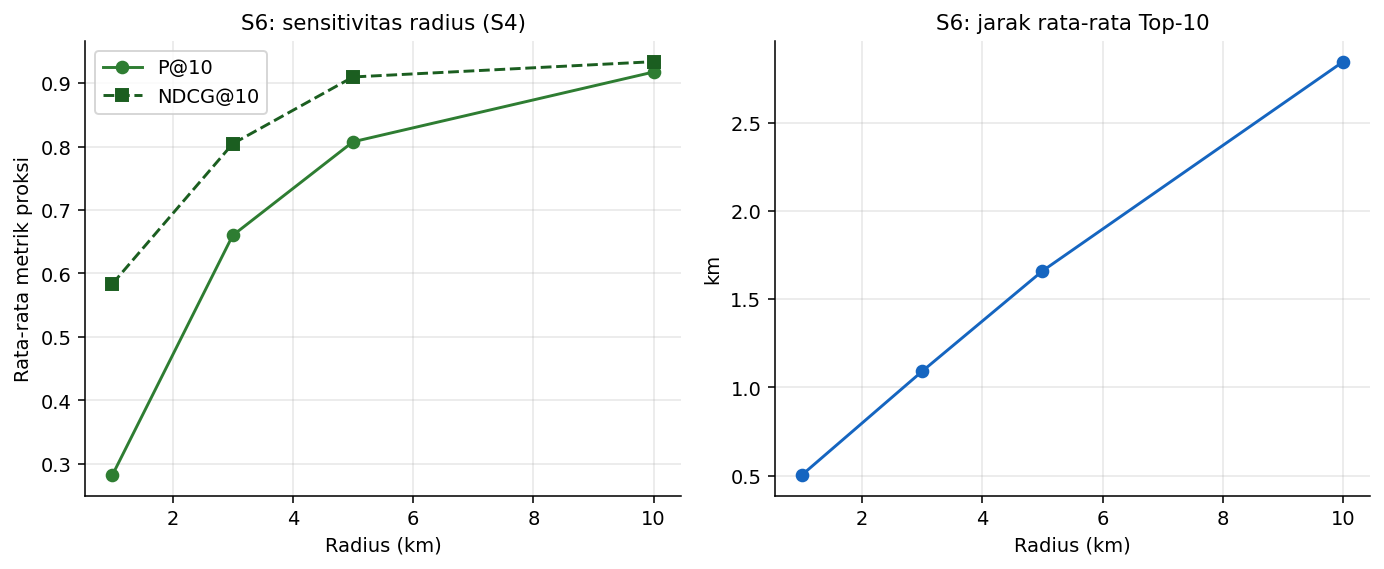

Sepuluh kombinasi bobot teratas menurut NDCG@10 proksi (15 kueri):


,peringkat,lokasi,kategori,rating,harga,n_kueri,precision_at_10_rata,ndcg_at_10_rata
0,1,0.2500,0.1500,0.6000,0.0000,15,0.7200,0.8901
1,2,0.2000,0.1000,0.6500,0.0500,15,0.7000,0.8858
2,3,0.3000,0.1500,0.5500,0.0000,15,0.7000,0.8850
3,4,0.2000,0.1000,0.6000,0.1000,15,0.6733,0.8846
4,5,0.2000,0.2000,0.6000,0.0000,15,0.7533,0.8836
5,6,0.2500,0.1500,0.5500,0.0500,15,0.7200,0.8834
6,7,0.3500,0.2000,0.4500,0.0000,15,0.7200,0.8829
7,8,0.4000,0.2500,0.3500,0.0000,15,0.7267,0.8827
8,9,0.2500,0.1500,0.5000,0.1000,15,0.7133,0.8827
9,10,0.3000,0.1500,0.5000,0.0500,15,0.6933,0.8825


Peringkat bobot bawaan S4 (0,35; 0,30; 0,20; 0,15) pada grid subset ini:


,peringkat,lokasi,kategori,rating,harga,n_kueri,precision_at_10_rata,ndcg_at_10_rata
0,125,0.3500,0.3000,0.2000,0.1500,15,0.7400,0.8659


In [6]:
agg = s6.groupby("radius_km", as_index=False).agg(
    n_kosong=("n_hasil", lambda s: int((s == 0).sum())),
    n_hasil_rata=("n_hasil", "mean"),
    P10=("precision_at_10", "mean"),
    NDCG10=("ndcg_at_10", "mean"),
    jarak_rata=("jarak_rata", "mean"),
)
display(agg.set_index("radius_km"))
display(Image(filename=str(LAPORAN / "sensitivitas_radius.png")))

print("Sepuluh kombinasi bobot teratas menurut NDCG@10 proksi (15 kueri):")
display(s5.head(10).reset_index(drop=True))

s4_baris = s5[(s5["lokasi"] - 0.35).abs() < 1e-9]
s4_baris = s4_baris[(s4_baris["kategori"] - 0.30).abs() < 1e-9]
s4_baris = s4_baris[(s4_baris["rating"] - 0.20).abs() < 1e-9]
s4_baris = s4_baris[(s4_baris["harga"] - 0.15).abs() < 1e-9]
print("Peringkat bobot bawaan S4 (0,35; 0,30; 0,20; 0,15) pada grid subset ini:")
display(s4_baris.reset_index(drop=True))


**Catatan S6 dan S5, tetap dalam kerangka proksi.**

- P@10 dan NDCG@10 proksi naik bersama radius. Sebagian karena kandidat bertambah, tetapi sebagian karena ambang “dekat” pada aturan proksi adalah \(R/2\): pada R = 10 km, item hingga 5 km sudah mendapat nilai 2 (jika syarat lain terpenuhi). Ini bias aturan, bukan bukti bahwa radius 10 km selalu lebih baik bagi pengguna.
- Dua kueri kosong pada R = 1 km (kategori atau anggaran terlalu ketat di sekitar titik itu).
- Pemenang grid S5 menekan rating sangat tinggi dan harga ke 0 (misalnya 0,25 / 0,15 / 0,60 / 0,00). Itu selaras dengan aturan proksi (nilai 2 mensyaratkan rating ≥ 4,7; harga tidak masuk rumus). **Bobot bawaan tidak akan diganti** berdasar grid ini. Grid hanya menunjukkan bahwa “mengoptimalkan proksi” akan mengabaikan harga — justru alasan proksi tidak layak menjadi penentu desain akhir.


## 8. Pemeriksaan rumus dan kasus Beji

Sel ini memastikan fungsi metrik dan mesin rekomendasi masih konsisten dengan definisi (bukan mengulang seluruh eksperimen).


In [7]:
from kuliner.evaluasi import dcg_at_k, ndcg_at_k, precision_at_k
from kuliner.recommender import muat_katalog, rekomendasi
from kuliner.config import PATH_BERSIH, PATH_DB

# Precision@5 = 3/5; NDCG@4 untuk [2, 1, 0, 2] dihitung manual di tes unit.
rel = [1, 0, 1, 0, 1]
assert abs(precision_at_k(rel, k=5) - 0.6) < 1e-12
print("Precision@5 [1,0,1,0,1] =", precision_at_k(rel, k=5))

rel4 = [2, 1, 0, 2]
print("NDCG@4 [2,1,0,2] =", round(ndcg_at_k(rel4, k=4), 6),
      "| DCG =", round(dcg_at_k(rel4, k=4), 6))

if PATH_DB.exists():
    data = muat_katalog(sumber="sqlite", path_db=PATH_DB, ulang=True)
else:
    data = muat_katalog(sumber="csv", path_csv=PATH_BERSIH, ulang=True)

q01 = skenario[skenario["id"] == "Q01"].iloc[0]
top = rekomendasi(
    float(q01.lat), float(q01.lon),
    radius_km=float(q01.radius_km),
    budget_maks=int(q01.budget_maks),
    rating_min=float(q01.rating_min),
    kategori_pilihan=["Bakmie"],
    k=3,
    data=data,
)
print("Q01 Top-3 (harus tetap dibuka oleh Bakmi Roxy, Depok):")
display(top[["peringkat", "nama", "kota", "kecamatan", "jarak_km", "skor"]].reset_index(drop=True))


Precision@5 [1,0,1,0,1] = 0.6
NDCG@4 [2,1,0,2] = 0.912878 | DCG = 4.922959
Q01 Top-3 (harus tetap dibuka oleh Bakmi Roxy, Depok):


,peringkat,nama,kota,kecamatan,jarak_km,skor
0,1,"Bakmi Roxy, Depok",Kota Depok,Beji,1.6041,0.2349
1,2,"Mie Ayam Bangka Koko, Kuliner Ceria",Kota Depok,Beji,1.7012,0.2442
2,3,"Seblak Seuhah Peed Mamah Ebot, Beji",Kota Depok,Pancoran Mas,1.6491,0.3636


## 9. Kesimpulan sementara dan rencana bagian 5

1. Terhadap baseline jarak dan baseline rating, S4 (dan model gabungan lain) unggul jelas pada Precision@10 dan NDCG@10 **proksi**; uji Wilcoxon berpasangan signifikan pada α = 0,05.
2. Di antara S2, S3, dan S4, perbedaannya kecil. Pada proksi, S2 unggul di Precision@10 dan S3 di NDCG@10; S4 tidak juara. Itu konsisten dengan fakta bahwa proksi tidak memakai harga.
3. S1 menghasilkan daftar terdekat dan paling beragam kategori, tetapi miskin irisan kategori (nilai proksi rendah).
4. Sensitivitas radius dan pemenang grid bobot *tidak* boleh langsung diangkat menjadi parameter final: keduanya ikut bias aturan proksi (ambang \(R/2\) dan penekanan rating, pengabaian harga).
5. **Klaim kualitas akhir ditunda** sampai ada penilaian responden (0/1/2) pada bagian 5. Fungsi `precision_at_k` dan `ndcg_at_k` sudah menerima nilai graded itu tanpa perubahan rumus. Precision akan memperlakukan 1 dan 2 sebagai relevan; NDCG memakai skala 0–2 utuh.

Untuk mengulang seluruh eksperimen (termasuk 969 kombinasi bobot):

```bash
python scripts/evaluasi_offline.py
```
